# Detecting DDoS Attacks using LSTM on the CIC-DDoS2019 Dataset

This notebook is the polished, presentation-oriented version of the validated project pipeline. It is designed to be readable in an academic setting while remaining executable from top to bottom on a **controlled subset** of CIC-DDoS2019.

**Stage covered here**
- a stable, verified notebook workflow on the audited subset used in Phases 1, 2, 2.5b, and 3
- emphasis on correctness, reproducibility, and methodological clarity rather than full-dataset scale

**Dataset slice used in the multiclass experiments**
- `01-12/DrDoS_DNS.csv`
- `01-12/DrDoS_NTP.csv`
- `01-12/DrDoS_NetBIOS.csv`
- `03-11/Portmap.csv`

**Notebook design principles**
- reuse the validated project logic rather than silently rewriting it
- keep the strict split logic and leakage warnings visible
- run safely on a controlled subset before any later scaling stage
- prefer loading saved validated artifacts for expensive phases so the notebook remains practical to execute

Methodological note: CIC-DDoS2019 is primarily a **tabular flow dataset**. The LSTM is therefore used through a justified sequence-construction proxy rather than a naturally sequence-labeled task.

In [1]:

# Imports and runtime configuration.
# The notebook reuses helper functions from the validated project script.

from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, Image, display

import ddos_lstm_project as project

warnings.filterwarnings('ignore')
project.set_global_seed(project.SEED)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)

BASE_DIR = Path.cwd()
PHASE2_OUTPUT_DIR = BASE_DIR / 'outputs_phase2_clean' / 'phase2_multiclass_subset'
PHASE1_OUTPUT_DIR = BASE_DIR / 'outputs' / 'phase1_dns_binary'
PHASE1_ABLATION_DIR = BASE_DIR / 'outputs' / 'phase1_ablation_no_inbound'
PHASE25_OUTPUT_DIR = BASE_DIR / 'outputs_phase25_groupaware' / 'phase25_multiclass_groupaware'

# Keep expensive model training optional by default.
# The notebook still shows the exact logic and loads validated saved artifacts.
RUN_EXPENSIVE_CELLS = False

phase2_config = next(cfg for cfg in project.default_phase_configs() if cfg.name == 'phase2_multiclass_subset')
phase1_config = next(cfg for cfg in project.default_phase_configs() if cfg.name == 'phase1_dns_binary')

print('Base directory:', BASE_DIR)
print('Phase 2 output directory:', PHASE2_OUTPUT_DIR)
print('RUN_EXPENSIVE_CELLS =', RUN_EXPENSIVE_CELLS)
print('Phase 2 files:', phase2_config.relative_files)
print('Phase 2.5 diagnostics directory:', PHASE25_OUTPUT_DIR)


Base directory: C:\Users\nourg\Downloads\archive (1)
Phase 2 output directory: C:\Users\nourg\Downloads\archive (1)\outputs_phase2_clean\phase2_multiclass_subset
RUN_EXPENSIVE_CELLS = False
Phase 2 files: ['01-12/DrDoS_DNS.csv', '01-12/DrDoS_NTP.csv', '01-12/DrDoS_NetBIOS.csv', '03-11/Portmap.csv']
Phase 2.5 diagnostics directory: C:\Users\nourg\Downloads\archive (1)\outputs_phase25_groupaware\phase25_multiclass_groupaware


## Runtime Notes and Colab Readiness

This notebook is structured to run both locally and in Google Colab, provided the working directory contains:
- `ddos_lstm_project.py`
- `ddos_lstm_project_notebook.ipynb`
- the required CIC-DDoS2019 CSV files
- the saved `outputs...` folders used by the later analysis sections

For a smooth Colab run:
1. mount Google Drive
2. change the working directory to the project folder
3. install the required Python libraries if they are not already available
4. keep `RUN_EXPENSIVE_CELLS = False` unless you intentionally want to retrain models

The notebook is intentionally configured around a **controlled subset** so that Stage 1 stays stable and presentation-ready before any larger-scale rerun.

In [2]:
# Optional Colab setup cell.
# Run this cell only in Google Colab, then set PROJECT_DIR to your folder.

# from google.colab import drive
# drive.mount('/content/drive')

# import os
# PROJECT_DIR = '/content/drive/MyDrive/ddos_project'
# os.chdir(PROJECT_DIR)

# !pip install -q numpy pandas scikit-learn matplotlib seaborn imbalanced-learn torch

## Project Context and Methodology

### Incremental Model Development
The project follows an incremental strategy instead of jumping directly to the full multi-gigabyte dataset.

1. **Phase 1** validated the full pipeline on a simpler binary task: `ATTACK` vs `BENIGN`.
2. **Phase 1 ablation** checked whether the results depended too heavily on `inbound`.
3. **Phase 2** expanded to multiclass classification across several attack families while keeping the subset manageable.
4. **Phase 2.5b** introduced the strongest feasible group-aware robustness check.
5. **Phase 3** analyzed shortcut features, model choice, and sequence design under strict evaluation.

### Why the notebook stays on a controlled subset
Stage 1 is intentionally limited to a smaller, audited subset so that we can verify:
- data loading and cleaning
- leakage-aware preprocessing
- split logic
- sequence construction
- model comparison and interpretation

This is the right scientific order: first confirm that the methodology is stable, then scale it.

### Why Phase 1 was binary
Binary classification made it easier to verify the whole pipeline first:
- data cleaning
- leakage handling
- train/validation/test split logic
- LSTM sequence construction
- tuning and evaluation

### Why Phase 2 moved to multiclass
Once the pipeline was validated, the next step was to distinguish between multiple DDoS attack types:
- `BENIGN`
- `DrDoS_DNS`
- `DrDoS_NTP`
- `DrDoS_NetBIOS`
- `Portmap`

### Why LSTM is used here
The dataset is mainly tabular flow data, not a native sequence dataset. The LSTM is therefore used through a **constructed temporal view**:
- group rows by `source_ip`
- order them by `timestamp`
- use short windows of prior flows to give temporal context

This is useful experimentally, but it should be interpreted honestly as a methodological approximation.

In [3]:

# Data loading with the same chunk-based helper used in the script.
# This is moderately expensive because it reads sampled chunks from large CSV files.

raw_df = project.load_phase_data(BASE_DIR, phase2_config)
raw_target_column = project.infer_target_column(raw_df.columns)

print('Raw shape:', raw_df.shape)
print('Raw target column:', raw_target_column)
display(raw_df.head())
display(raw_df[raw_target_column].astype(str).str.strip().value_counts().rename_axis('label').to_frame('count'))


Raw shape: (200000, 89)
Raw target column:  Label


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label,__source_file__
0,425,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5,634,192.168.50.1,60495,17,2018-12-01 10:51:39.813448,28415,97,0,42680.0,0.0,440.0,440.0,440.0,0.0,0.0,0.0,0.0,0.0,1.502024e+06,3413.689952,295.989583,500.959301,3596.0,1.0,28415.0,295.989583,500.959301,3596.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,-97,0,3413.689952,0.0,440.0,440.0,440.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,444.536082,440.0,0.0,-97,0,0,0,0,0,0,97,42680,0,0,-1,-1,96,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,01-12/DrDoS_DNS.csv
1,430,172.16.0.5-192.168.50.1-60495-634-17,192.168.50.1,634,172.16.0.5,60495,17,2018-12-01 10:51:39.820842,2,2,0,880.0,0.0,440.0,440.0,440.0,0.0,0.0,0.0,0.0,0.0,4.400000e+08,1000000.000000,2.000000,0.000000,2.0,2.0,2.0,2.000000,0.000000,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,-2,0,1000000.000000,0.0,440.0,440.0,440.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,660.000000,440.0,0.0,-2,0,0,0,0,0,0,2,880,0,0,-1,-1,1,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,DrDoS_DNS,01-12/DrDoS_DNS.csv
2,1654,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5,634,192.168.50.1,46391,17,2018-12-01 10:51:39.852499,48549,200,0,88000.0,0.0,440.0,440.0,440.0,0.0,0.0,0.0,0.0,0.0,1.812602e+06,4119.549321,243.964824,578.101371,5418.0,1.0,48549.0,243.964824,578.101371,5418.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,-200,0,4119.549321,0.0,440.0,440.0,440.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,442.200000,440.0,0.0,-200,0,0,0,0,0,0,200,88000,0,0,-1,-1,199,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,01-12/DrDoS_DNS.csv
3,2927,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5,634,192.168.50.1,11894,17,2018-12-01 10:51:39.890213,48337,200,0,88000.0,0.0,440.0,440.0,440.0,0.0,0.0,0.0,0.0,0.0,1.820552e+06,4137.617146,242.899497,485.292695,3337.0,1.0,48337.0,242.899497,485.292695,3337.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,-200,0,4137.617146,0.0,440.0,440.0,440.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,442.200000,440.0,0.0,-200,0,0,0,0,0,0,200,88000,0,0,-1,-1,199,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,01-12/DrDoS_DNS.csv
4,694,172.16.0.5-192.168.50.1-634-27878-17,172.16.0.5,634,192.168.50.1,27878,17,2018-12-01 10:51:39.941151,32026,200,0,88000.0,0.0,440.0,440.0,440.0,0.0,0.0,0.0,0.0,0.0,2.747767e+06,6244.925998,160.934673,196.891271,1236.0,0.0,32026.0,160.934673,196.891271,1236.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,-200,0,6244.925998,0.0,440.0,440.0,440.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,442.200000,440.0,0.0,-200,0,0,0,0,0,0,200,88000,0,0,-1,-1,199,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,01-12/DrDoS_DNS.csv


,count
label,
DrDoS_NetBIOS,49839
DrDoS_DNS,48298
Portmap,45283
DrDoS_NTP,37653
BENIGN,18927



## Data Exploration

The next cells inspect the combined multiclass subset before cleaning. The goal is to show the same diagnostic logic already validated in the script:
- schema inspection
- missing values
- duplicate rows
- duplicate columns
- class imbalance
- suspicious or leakage-prone fields


In [4]:

# Basic schema inspection.

schema_overview = pd.DataFrame({
    'column': raw_df.columns,
    'dtype': raw_df.dtypes.astype(str).values,
    'missing_count': raw_df.isna().sum().values,
})

display(schema_overview.head(20))
print('Approximate raw memory usage (MB):', round(raw_df.memory_usage(deep=True).sum() / (1024 ** 2), 2))
print('Duplicate row count:', int(raw_df.duplicated().sum()))
print('Duplicate column candidates:', project.find_duplicate_columns(raw_df))


,column,dtype,missing_count
0,Unnamed: 0,int64,0
1,Flow ID,object,0
2,Source IP,object,0
3,Source Port,int64,0
4,Destination IP,object,0
5,Destination Port,int64,0
6,Protocol,int64,0
7,Timestamp,object,0
8,Flow Duration,int64,0
9,Total Fwd Packets,int64,0


Approximate raw memory usage (MB): 223.05


Duplicate row count: 0


Duplicate column candidates: [' Fwd URG Flags', ' Bwd URG Flags', 'FIN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ECE Flag Count', ' Fwd Header Length.1', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate', 'Subflow Fwd Packets', ' Subflow Bwd Packets']


In [5]:

# Focused exploration: class balance, missing values, and suspicious columns.

raw_class_distribution = raw_df[raw_target_column].astype(str).str.strip().value_counts().sort_values(ascending=False)
missing_ratio = (raw_df.isna().mean().sort_values(ascending=False) * 100).rename('missing_pct')
suspicious_columns = list(project.identify_leakage_columns(raw_df.columns).keys())

print('Class distribution:')
display(raw_class_distribution.to_frame('count'))
print('\nTop missing ratios (%):')
display(missing_ratio[missing_ratio > 0].head(15).to_frame())
print('\nSuspicious / leakage-prone columns detected:')
print(suspicious_columns)


Class distribution:


,count
Label,
DrDoS_NetBIOS,49839
DrDoS_DNS,48298
Portmap,45283
DrDoS_NTP,37653
BENIGN,18927



Top missing ratios (%):


,missing_pct
Flow Bytes/s,0.006



Suspicious / leakage-prone columns detected:
['Unnamed: 0', 'Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Timestamp', 'SimillarHTTP']



### Brief observations

- The selected files integrate into a consistent schema.
- The combined subset is imbalanced, especially for `BENIGN`.
- Several columns are operational identifiers rather than stable predictive features, especially `Flow ID`, IP fields, ports, and `Timestamp`.
- `simillarhttp` is stored as an object-like field and needs conversion handling.



## Data Cleaning and Preprocessing

The notebook now reuses the project cleaning helpers directly.

Main goals:
- standardize column names
- convert problematic fields such as `simillarhttp`
- remove leakage-prone columns from model inputs
- handle missing and infinite values
- remove duplicate, constant, and near-constant columns
- prepare label encoding and train-only scaling

Important: `source_ip` and `timestamp` are kept only as **metadata** for sequence construction, not as model input features.


In [6]:

# Run the same validated cleaning logic used in the script.

cleaned_df, cleaning_summary = project.preprocess_dataframe(raw_df, phase2_config)
target_column = cleaning_summary['target_column']

print('Cleaned shape:', cleaned_df.shape)
print('Target column:', target_column)
print('Task type:', cleaning_summary['task_type'])
print('Converted numeric-like columns:', cleaning_summary['converted_numeric_columns'])
print('Constant columns removed:', cleaning_summary['constant_columns_removed'])
print('Near-constant columns removed:', cleaning_summary['near_constant_columns_removed'])
print('Leakage columns identified:', list(cleaning_summary['leakage_columns_removed'].keys()))

display(pd.Series(cleaning_summary['label_distribution_after_cleaning'], name='count').to_frame())


Cleaned shape: (200000, 66)
Target column: label
Task type: multiclass
Converted numeric-like columns: ['simillarhttp']
Constant columns removed: ['bwd_psh_flags']
Near-constant columns removed: ['bwd_psh_flags', 'syn_flag_count']
Leakage columns identified: ['unnamed_0', 'flow_id', 'source_ip', 'source_port', 'destination_ip', 'destination_port', 'timestamp', 'simillarhttp']


,count
DrDoS_NetBIOS,49839
DrDoS_DNS,48298
Portmap,45283
DrDoS_NTP,37653
BENIGN,18927


In [7]:

# Prepare the train/validation/test split and training-only preprocessing.

train_df, val_df, test_df = project.stratified_split(cleaned_df, target_column)
prepared = project.prepare_model_inputs(train_df, val_df, test_df, target_column, PHASE2_OUTPUT_DIR, phase2_config)

print('Train shape:', train_df.shape)
print('Validation shape:', val_df.shape)
print('Test shape:', test_df.shape)
print('Feature count used for modeling:', len(prepared['feature_columns']))
print('Classes:', prepared['label_encoder'].classes_.tolist())
print('Class weights:', prepared['class_weights'])


Train shape: (140000, 66)
Validation shape: (30000, 66)
Test shape: (30000, 66)
Feature count used for modeling: 62
Classes: ['BENIGN', 'DrDoS_DNS', 'DrDoS_NTP', 'DrDoS_NetBIOS', 'Portmap']
Class weights: {3: 0.8025912230916961, 4: 0.8833364881065051, 2: 1.0623363812269986, 0: 2.1133670465695524, 1: 0.8281818450708391}



## Sequence Construction for LSTM

The LSTM does not receive raw identifiers. Instead, metadata is used only to define order:
- group rows by `source_ip`
- sort each group by `timestamp`
- build a fixed-length sequence of recent flows
- left-pad with zeros when there is insufficient history

This keeps ordering information while avoiding direct use of identifiers as predictive features.


In [8]:

# Build example sequences for the training split to show the input structure.

sequence_length_demo = 5
X_train_seq_demo, y_train_seq_demo = project.build_sequences(
    prepared['X_train'], prepared['y_train'], prepared['train_df'], sequence_length_demo
)

print('Demo sequence length:', sequence_length_demo)
print('LSTM input shape:', X_train_seq_demo.shape)
print('LSTM target shape:', y_train_seq_demo.shape)
print('One sample sequence tensor shape:', X_train_seq_demo[0].shape)


Demo sequence length: 5
LSTM input shape: (140000, 5, 62)
LSTM target shape: (140000,)
One sample sequence tensor shape: (5, 62)



## Train / Validation / Test Split

The current project uses a **row-wise stratified split**.

Why this is reasonable for now:
- each class stays represented in train, validation, and test
- preprocessing is fitted on training only
- sequences are built separately inside each split

Current limitation:
- this is not a strict group-based split by `source_ip` or capture scenario, so overlap of IPs across splits can still make results optimistic


In [9]:

# Overlap diagnostics for the current split strategy.

train_ips = set(train_df['source_ip'].dropna().astype(str))
val_ips = set(val_df['source_ip'].dropna().astype(str))
test_ips = set(test_df['source_ip'].dropna().astype(str))

overlap_summary = pd.DataFrame([
    {'split_pair': 'train_val', 'overlap_count': len(train_ips & val_ips)},
    {'split_pair': 'train_test', 'overlap_count': len(train_ips & test_ips)},
    {'split_pair': 'val_test', 'overlap_count': len(val_ips & test_ips)},
])

display(overlap_summary)
print('Unique source_ip counts:')
print({'train': len(train_ips), 'val': len(val_ips), 'test': len(test_ips)})


,split_pair,overlap_count
0,train_val,206
1,train_test,178
2,val_test,131


Unique source_ip counts:
{'train': 430, 'val': 241, 'test': 207}



## Baseline Model

The project baseline is Logistic Regression with class weights.

This cell is expensive if retraining is enabled. By default, it loads the validated saved Phase 2 metrics so the notebook remains practical to run end to end.


In [10]:

# Baseline training or loading of saved validated results.

if RUN_EXPENSIVE_CELLS:
    baseline_model, baseline_tuning = project.train_logistic_baseline(
        prepared['X_train'], prepared['y_train'], prepared['X_val'], prepared['y_val'], prepared['class_weights']
    )
    baseline_pred = baseline_model.predict(prepared['X_test'])
    baseline_proba = baseline_model.predict_proba(prepared['X_test'])
    baseline_metrics = project.evaluate_classifier(
        'logistic_regression', prepared['y_test'], baseline_pred, baseline_proba, prepared['label_encoder'].classes_
    )
    baseline_metrics['tuning'] = baseline_tuning
else:
    baseline_metrics = json.loads((PHASE2_OUTPUT_DIR / 'baseline_test_metrics.json').read_text(encoding='utf-8'))

baseline_report = pd.DataFrame(baseline_metrics['classification_report']).T
print('Baseline accuracy:', baseline_metrics['accuracy'])
print('Baseline weighted F1:', baseline_metrics['f1_weighted'])
display(baseline_report)


Baseline accuracy: 0.9067
Baseline weighted F1: 0.9058553178491531


,precision,recall,f1-score,support
BENIGN,0.884506,0.987319,0.933089,2839.0000
DrDoS_DNS,0.904264,0.787440,0.841818,7245.0000
DrDoS_NTP,0.816484,0.882259,0.848098,5648.0000
DrDoS_NetBIOS,0.938313,0.946094,0.942187,7476.0000
Portmap,0.964540,0.977179,0.970818,6792.0000
accuracy,0.906700,0.906700,0.906700,0.9067
macro avg,0.901621,0.916058,0.907202,30000.0000
weighted avg,0.907999,0.906700,0.905855,30000.0000


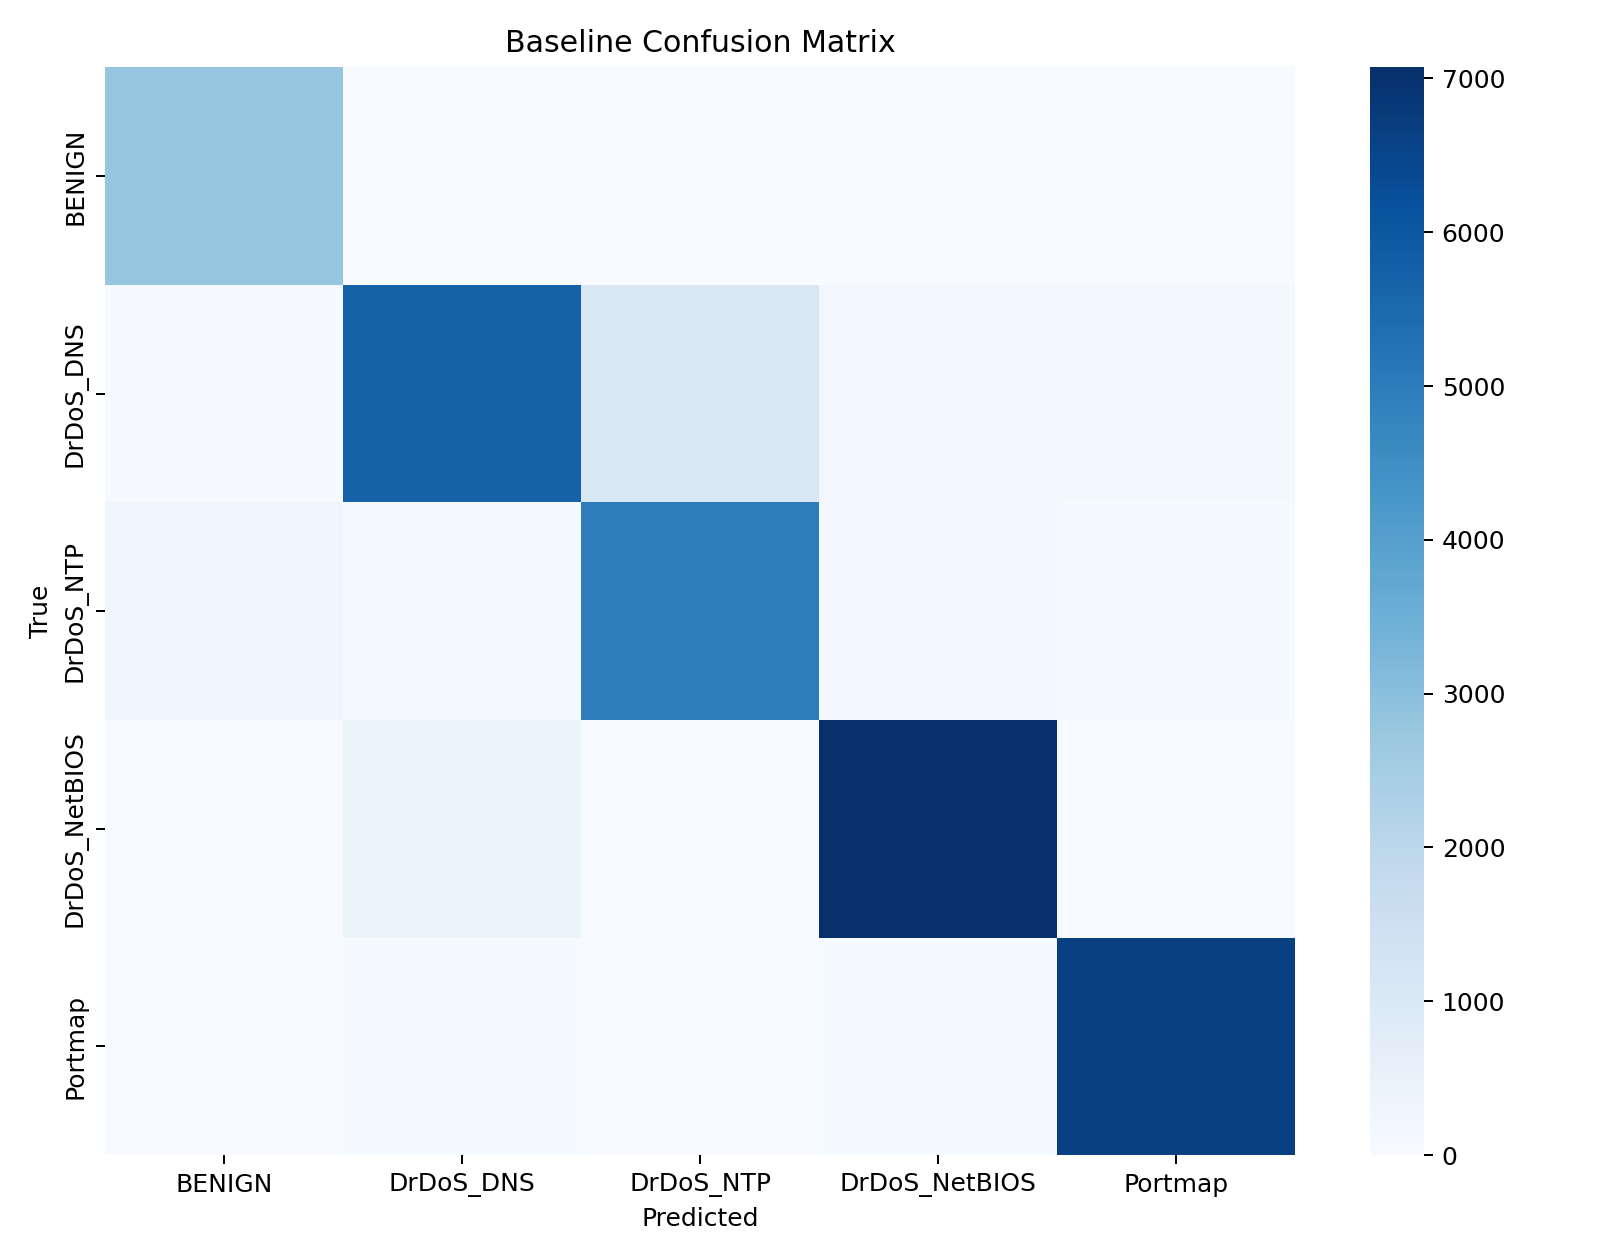

In [11]:

# Show the saved baseline confusion matrix plot.

display(Image(filename=str(PHASE2_OUTPUT_DIR / 'baseline_confusion_matrix.png')))



## LSTM Model

The LSTM uses the validated project architecture:
- fixed-length sequence input
- one LSTM layer
- dropout
- feed-forward classifier head
- class-weighted cross-entropy
- early stopping through validation monitoring inside the training loop

This is also an expensive section. By default, the notebook loads the validated saved results and plots.


In [12]:

# LSTM training or loading of saved validated results.

if RUN_EXPENSIVE_CELLS:
    best_lstm_model, best_lstm_config, best_lstm_history = project.train_lstm_with_tuning(
        phase2_config, prepared, PHASE2_OUTPUT_DIR
    )
    X_test_seq, y_test_seq = project.build_sequences(
        prepared['X_test'], prepared['y_test'], prepared['test_df'], int(best_lstm_config['sequence_length'])
    )
    test_loader = project.create_data_loader(X_test_seq, y_test_seq, int(best_lstm_config['batch_size']), False)
    lstm_pred, lstm_proba = project.predict_with_lstm(best_lstm_model, test_loader, project.torch.device('cpu'))
    lstm_metrics = project.evaluate_classifier(
        'lstm', y_test_seq, lstm_pred, lstm_proba, prepared['label_encoder'].classes_
    )
    lstm_metrics['best_config'] = best_lstm_config
else:
    lstm_metrics = json.loads((PHASE2_OUTPUT_DIR / 'lstm_test_metrics.json').read_text(encoding='utf-8'))

lstm_report = pd.DataFrame(lstm_metrics['classification_report']).T
print('LSTM accuracy:', lstm_metrics['accuracy'])
print('LSTM weighted F1:', lstm_metrics['f1_weighted'])
print('Best configuration:', lstm_metrics['best_config'])
display(lstm_report)


LSTM accuracy: 0.9975333333333334
LSTM weighted F1: 0.9975336943721372
Best configuration: {'sequence_length': 10, 'hidden_size': 64, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 512, 'best_validation_weighted_f1': 0.998500345808756, 'epochs_ran': 12}


,precision,recall,f1-score,support
BENIGN,0.996129,0.997182,0.996656,2839.000000
DrDoS_DNS,0.996278,0.997516,0.996896,7245.000000
DrDoS_NTP,0.994884,0.998584,0.996731,5648.000000
DrDoS_NetBIOS,0.999866,0.999197,0.999532,7476.000000
Portmap,0.999113,0.994994,0.997049,6792.000000
accuracy,0.997533,0.997533,0.997533,0.997533
macro avg,0.997254,0.997495,0.997373,30000.000000
weighted avg,0.997538,0.997533,0.997534,30000.000000


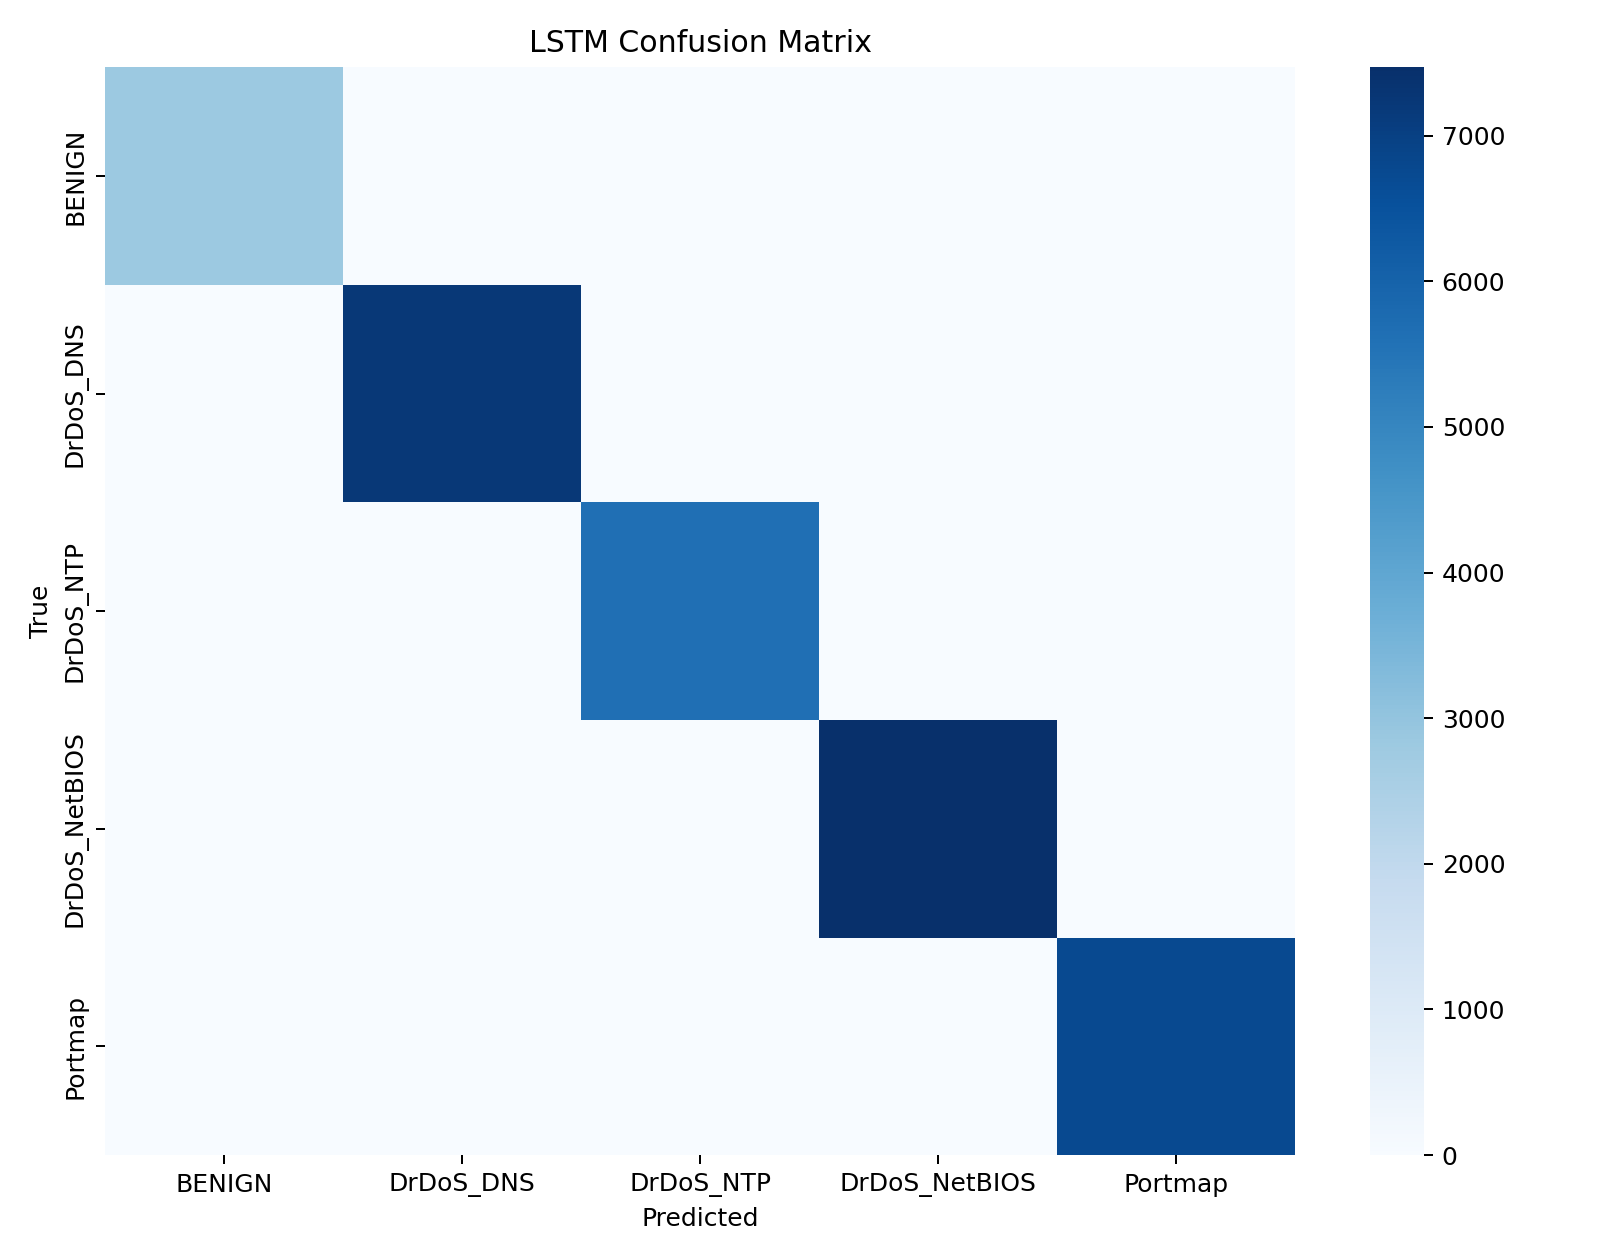

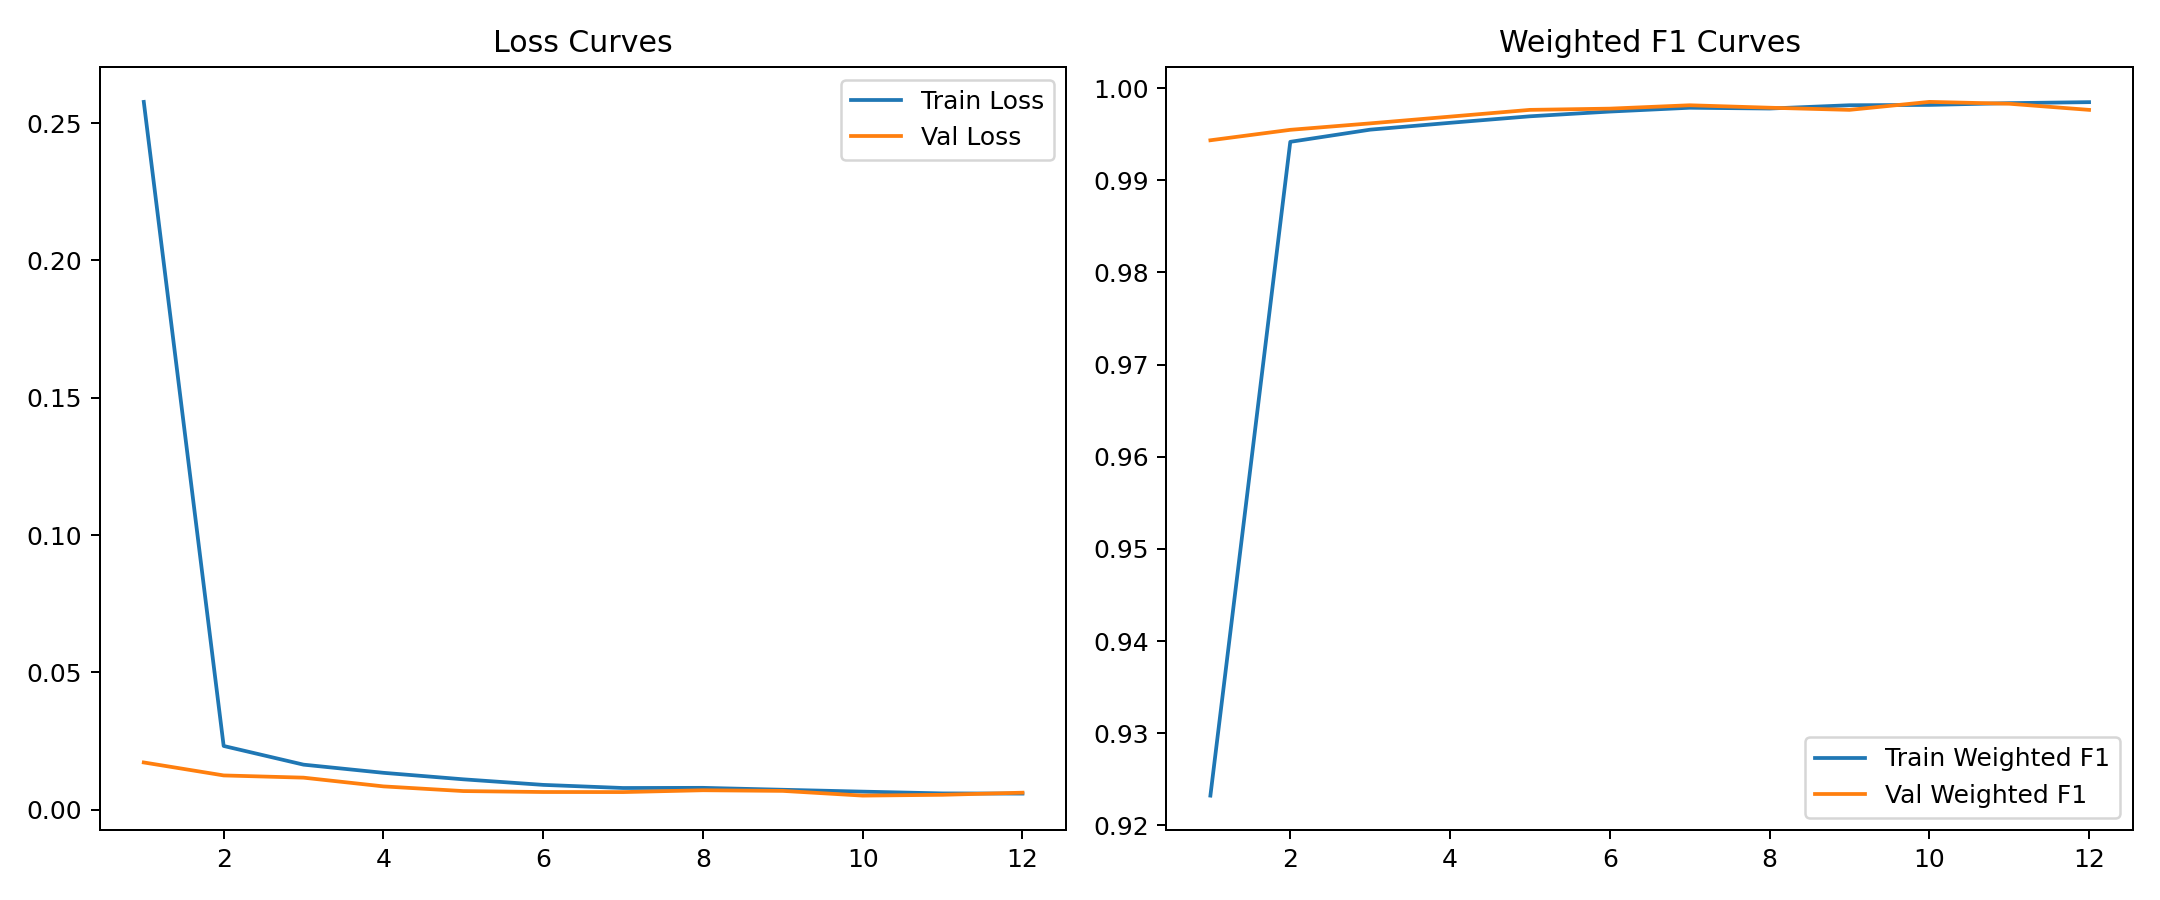

In [13]:

# Show the saved LSTM confusion matrix and training curves.

display(Image(filename=str(PHASE2_OUTPUT_DIR / 'lstm_confusion_matrix.png')))
display(Image(filename=str(PHASE2_OUTPUT_DIR / 'lstm_training_curves.png')))



## Hyperparameter Tuning Summary

The project tuning remains intentionally practical rather than exhaustive. In Phase 2, the LSTM search focused on:
- sequence length
- dropout
- hidden size
- learning rate
- batch size

The goal is to see whether a small number of justified changes improves validation performance, not to run a blind search.


In [14]:

# Summarize the saved Phase 2 LSTM tuning results.

tuning_summary = json.loads((PHASE2_OUTPUT_DIR / 'lstm_tuning_results.json').read_text(encoding='utf-8'))
tuning_df = pd.DataFrame(tuning_summary['results']).sort_values('best_validation_weighted_f1', ascending=False)

display(tuning_df)
print('Best configuration:')
print(tuning_summary['best'])


,sequence_length,hidden_size,dropout,learning_rate,batch_size,best_validation_weighted_f1,epochs_ran
2,10,64,0.20,0.001,512,0.998500,12
3,10,64,0.35,0.001,512,0.997934,9
1,5,64,0.35,0.001,512,0.995834,12
0,5,64,0.20,0.001,512,0.995669,12


Best configuration:
{'sequence_length': 10, 'hidden_size': 64, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 512, 'best_validation_weighted_f1': 0.998500345808756, 'epochs_ran': 12}



## Phase 2.5 Group-Aware Split Diagnostic

Phase 2.5 did not become a new training/evaluation run because the strict requested protocol was not feasible on this dataset slice.

What was checked:
- strict grouping by `source_ip`
- zero overlap requirement across train / validation / test
- class coverage under a true 3-way group-aware split

What was observed from the real data:
- each attack class appears in only two unique `source_ip` groups
- therefore a strict 3-way `source_ip` split cannot keep all target classes represented in all splits
- this is a structural dataset limitation, not a coding issue


In [15]:

# Load and summarize the saved Phase 2.5 diagnostics.

phase25_split = json.loads((PHASE25_OUTPUT_DIR / 'split_summary.json').read_text(encoding='utf-8'))
phase25_comparison = json.loads((PHASE25_OUTPUT_DIR / 'phase2_comparison_summary.json').read_text(encoding='utf-8'))

phase25_feasibility_df = pd.DataFrame([
    {
        'class': cls,
        'unique_source_ip': count,
        'feasible_for_3_way_split': count >= phase25_split['sample_feasibility']['num_splits_required'],
    }
    for cls, count in phase25_split['sample_feasibility']['unique_groups_per_class'].items()
]).sort_values(['feasible_for_3_way_split', 'unique_source_ip', 'class'])

phase25_top_groups_df = pd.DataFrame(phase25_split['sample_top_source_ip_class_table'])

print('Phase 2.5 status:', phase25_split['status'])
print('Requested group column:', phase25_split['requested_group_column'])
print('Comparison status:', phase25_comparison['comparison_status'])
print('Reason:', phase25_split['reason'])
print('Recommended next step:', phase25_split['recommended_next_step'])

display(phase25_feasibility_df)
display(phase25_top_groups_df.head(10))


Phase 2.5 status: infeasible_for_strict_three_way_group_split
Requested group column: source_ip
Comparison status: not_comparable_under_requested_protocol
Reason: Strict train/validation/test splitting by source_ip is not feasible for this four-file multiclass setup. Each attack class appears in only two unique source_ip groups across the audited files, so at least one split would necessarily miss one or more attack classes.
Recommended next step: Use a two-way group-aware train/test protocol, or switch the grouping unit to a higher-level capture/session entity if available. Do not claim strict three-way source_ip-aware generalization for this dataset slice.


,class,unique_source_ip,feasible_for_3_way_split
1,DrDoS_DNS,2,False
2,DrDoS_NTP,2,False
3,DrDoS_NetBIOS,2,False
4,Portmap,2,False
0,BENIGN,485,True


,source_ip,BENIGN,DrDoS_DNS,DrDoS_NTP,DrDoS_NetBIOS,Portmap,total_rows,num_classes
0,172.16.0.5,0,47300,36641,49830,44852,178623,4
1,192.168.50.6,5730,0,0,0,0,5730,1
2,192.168.50.8,4786,0,0,0,0,4786,1
3,192.168.50.7,4439,0,0,0,0,4439,1
4,192.168.50.1,64,998,1012,9,0,2083,4
5,192.168.50.4,20,0,0,0,431,451,2
6,74.208.236.171,405,0,0,0,0,405,1
7,192.168.50.9,348,0,0,0,0,348,1
8,72.21.91.29,99,0,0,0,0,99,1
9,192.168.50.253,76,0,0,0,0,76,1



## Results Comparison

This section compares:
- baseline vs LSTM in Phase 2
- Phase 1 vs Phase 2 headline metrics
- Phase 2.5 group-aware feasibility diagnostics
- hardest and easiest classes in the current multiclass setting


In [16]:

# Compare the two Phase 2 models and bring in the saved Phase 1 reference metrics.

phase1_baseline = json.loads((PHASE1_OUTPUT_DIR / 'baseline_test_metrics.json').read_text(encoding='utf-8'))
phase1_lstm = json.loads((PHASE1_OUTPUT_DIR / 'lstm_test_metrics.json').read_text(encoding='utf-8'))
phase1_ablation = json.loads((PHASE1_ABLATION_DIR / 'ablation_summary.json').read_text(encoding='utf-8'))
phase25_split = json.loads((PHASE25_OUTPUT_DIR / 'split_summary.json').read_text(encoding='utf-8'))
phase25_comparison = json.loads((PHASE25_OUTPUT_DIR / 'phase2_comparison_summary.json').read_text(encoding='utf-8'))

comparison_df = pd.DataFrame([
    {'phase': 'Phase 1', 'model': 'Baseline', 'accuracy': phase1_baseline['accuracy'], 'weighted_f1': phase1_baseline['f1_weighted']},
    {'phase': 'Phase 1', 'model': 'LSTM', 'accuracy': phase1_lstm['accuracy'], 'weighted_f1': phase1_lstm['f1_weighted']},
    {'phase': 'Phase 2', 'model': 'Baseline', 'accuracy': baseline_metrics['accuracy'], 'weighted_f1': baseline_metrics['f1_weighted']},
    {'phase': 'Phase 2', 'model': 'LSTM', 'accuracy': lstm_metrics['accuracy'], 'weighted_f1': lstm_metrics['f1_weighted']},
])

def class_f1_table(metrics_dict):
    report = metrics_dict['classification_report']
    rows = []
    for cls, values in report.items():
        if cls in {'accuracy', 'macro avg', 'weighted avg'}:
            continue
        rows.append({'class': cls, 'f1': values['f1-score'], 'recall': values['recall'], 'precision': values['precision']})
    return pd.DataFrame(rows).sort_values('f1')

baseline_class_f1 = class_f1_table(baseline_metrics)
lstm_class_f1 = class_f1_table(lstm_metrics)

print('Phase 1 ablation without inbound:')
print(phase1_ablation)
print('\nPhase 2.5 group-aware diagnostic:')
print({
    'status': phase25_split['status'],
    'requested_group_column': phase25_split['requested_group_column'],
    'unique_groups_per_class': phase25_split['sample_feasibility']['unique_groups_per_class'],
    'infeasible_classes': phase25_split['sample_feasibility']['infeasible_classes'],
    'comparison_status': phase25_comparison['comparison_status'],
})
print('Phase 2.5 interpretation:', phase25_split['reason'])
print('\nPhase comparison:')
display(comparison_df)
print('Baseline hardest class:', baseline_class_f1.iloc[0].to_dict())
print('Baseline easiest class:', baseline_class_f1.iloc[-1].to_dict())
print('LSTM hardest class:', lstm_class_f1.iloc[0].to_dict())
print('LSTM easiest class:', lstm_class_f1.iloc[-1].to_dict())
display(baseline_class_f1)
display(lstm_class_f1)


Phase 1 ablation without inbound:
{'feature_removed': 'inbound', 'cleaned_shape_without_inbound': [80000, 55], 'baseline': {'accuracy': 0.9926666666666667, 'f1_weighted': 0.9931702850465914, 'roc_auc': 0.9954607805049387, 'pr_auc': 0.9596681060217298}, 'lstm': {'accuracy': 0.9996666666666667, 'f1_weighted': 0.9996673009822448, 'roc_auc': 0.9999810408506471, 'pr_auc': 0.999190950584363, 'best_config': {'sequence_length': 10, 'hidden_size': 64, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 256, 'best_validation_weighted_f1': 1.0, 'epochs_ran': 11}}}

Phase 2.5 group-aware diagnostic:
{'status': 'infeasible_for_strict_three_way_group_split', 'requested_group_column': 'source_ip', 'unique_groups_per_class': {'BENIGN': 485, 'DrDoS_DNS': 2, 'DrDoS_NTP': 2, 'DrDoS_NetBIOS': 2, 'Portmap': 2}, 'infeasible_classes': {'DrDoS_DNS': 2, 'DrDoS_NTP': 2, 'DrDoS_NetBIOS': 2, 'Portmap': 2}, 'comparison_status': 'not_comparable_under_requested_protocol'}
Phase 2.5 interpretation: Strict train/val

,phase,model,accuracy,weighted_f1
0,Phase 1,Baseline,0.993917,0.994260
1,Phase 1,LSTM,0.999750,0.999750
2,Phase 2,Baseline,0.906700,0.905855
3,Phase 2,LSTM,0.997533,0.997534


Baseline hardest class: {'class': 'DrDoS_DNS', 'f1': 0.841817913531061, 'recall': 0.7874396135265701, 'precision': 0.9042637501981297}
Baseline easiest class: {'class': 'Portmap', 'f1': 0.9708184012286989, 'recall': 0.9771790341578327, 'precision': 0.9645400377852056}
LSTM hardest class: {'class': 'BENIGN', 'f1': 0.9966555183946488, 'recall': 0.9971821063754843, 'precision': 0.9961294862772695}
LSTM easiest class: {'class': 'DrDoS_NetBIOS', 'f1': 0.999531678597712, 'recall': 0.9991974317817014, 'precision': 0.9998661491098916}


,class,f1,recall,precision
1,DrDoS_DNS,0.841818,0.787440,0.904264
2,DrDoS_NTP,0.848098,0.882259,0.816484
0,BENIGN,0.933089,0.987319,0.884506
3,DrDoS_NetBIOS,0.942187,0.946094,0.938313
4,Portmap,0.970818,0.977179,0.964540


,class,f1,recall,precision
0,BENIGN,0.996656,0.997182,0.996129
2,DrDoS_NTP,0.996731,0.998584,0.994884
1,DrDoS_DNS,0.996896,0.997516,0.996278
4,Portmap,0.997049,0.994994,0.999113
3,DrDoS_NetBIOS,0.999532,0.999197,0.999866



## Phase 2.5b Strict Group-Aware Train/Test Robustness Check

Phase 2.5 showed that a strict **3-way** `source_ip`-aware split was not feasible for this dataset slice.

Why it was infeasible:
- each attack class appears in only **2 unique `source_ip` values**
- a true `train / validation / test` group-aware split would therefore leave at least one split without one or more attack classes

For that reason, **Phase 2.5b** was designed as the strongest feasible follow-up:
- strict **2-way** group-aware split by `source_ip`
- `train` and `test` only
- zero `source_ip` overlap between train and test
- internal validation kept only inside the training partition for model selection

This makes Phase 2.5b the most meaningful robustness check currently available for this four-file multiclass setup.


In [17]:

# Load the saved Phase 2.5b artifacts.

PHASE25B_OUTPUT_DIR = BASE_DIR / 'outputs_phase25b_groupaware_train_test' / 'phase25b_multiclass_groupaware_train_test'

phase25b_split = json.loads((PHASE25B_OUTPUT_DIR / 'split_summary.json').read_text(encoding='utf-8'))
phase25b_baseline = json.loads((PHASE25B_OUTPUT_DIR / 'baseline_test_metrics.json').read_text(encoding='utf-8'))
phase25b_lstm = json.loads((PHASE25B_OUTPUT_DIR / 'lstm_test_metrics.json').read_text(encoding='utf-8'))
phase25b_comparison = json.loads((PHASE25B_OUTPUT_DIR / 'phase2_comparison_summary.json').read_text(encoding='utf-8'))
phase25b_summary = json.loads((PHASE25B_OUTPUT_DIR / 'phase_summary.json').read_text(encoding='utf-8'))

print('Phase 2.5b split strategy:', phase25b_split['split_strategy'])
print('Group column:', phase25b_split['group_column'])
print('Train/test source_ip overlap:', phase25b_split['group_overlap']['train_test'])
print('Train unique source_ip:', phase25b_split['unique_group_counts']['train'])
print('Test unique source_ip:', phase25b_split['unique_group_counts']['test'])


Phase 2.5b split strategy: group_aware_train_test
Group column: source_ip
Train/test source_ip overlap: 0
Train unique source_ip: 42
Test unique source_ip: 444


In [18]:

# Display the main Phase 2.5b metrics in a compact table.

phase25b_metrics_table = pd.DataFrame([
    {
        'model': 'Baseline',
        'accuracy': phase25b_baseline['accuracy'],
        'weighted_f1': phase25b_baseline['f1_weighted'],
        'macro_f1': phase25b_baseline['f1_macro'],
        'roc_auc_ovr_weighted': phase25b_baseline.get('roc_auc_ovr_weighted'),
        'pr_auc_weighted': phase25b_baseline.get('pr_auc_weighted'),
    },
    {
        'model': 'LSTM',
        'accuracy': phase25b_lstm['accuracy'],
        'weighted_f1': phase25b_lstm['f1_weighted'],
        'macro_f1': phase25b_lstm['f1_macro'],
        'roc_auc_ovr_weighted': phase25b_lstm.get('roc_auc_ovr_weighted'),
        'pr_auc_weighted': phase25b_lstm.get('pr_auc_weighted'),
    },
]).round(4)

test_distribution_df = pd.DataFrame([
    {'class': cls, 'test_support': count}
    for cls, count in phase25b_split['class_distribution']['test'].items()
]).sort_values('test_support', ascending=False)

display(phase25b_metrics_table)
display(test_distribution_df)


,model,accuracy,weighted_f1,macro_f1,roc_auc_ovr_weighted,pr_auc_weighted
0,Baseline,0.3261,0.2985,0.0984,0.1747,0.3050
1,LSTM,0.6050,0.4625,0.1627,0.4801,0.4254


,class,test_support
0,BENIGN,3785
1,DrDoS_NTP,1012
2,DrDoS_DNS,998
3,Portmap,431
4,DrDoS_NetBIOS,9


In [19]:

# Compare Phase 2 row-wise results against Phase 2.5b strict group-aware train/test results.

phase2_vs_phase25b = pd.DataFrame([
    {
        'phase': 'Phase 2',
        'model': 'Baseline',
        'accuracy': baseline_metrics['accuracy'],
        'weighted_f1': baseline_metrics['f1_weighted'],
        'macro_f1': baseline_metrics['classification_report']['macro avg']['f1-score'],
    },
    {
        'phase': 'Phase 2.5b',
        'model': 'Baseline',
        'accuracy': phase25b_baseline['accuracy'],
        'weighted_f1': phase25b_baseline['f1_weighted'],
        'macro_f1': phase25b_baseline['f1_macro'],
    },
    {
        'phase': 'Phase 2',
        'model': 'LSTM',
        'accuracy': lstm_metrics['accuracy'],
        'weighted_f1': lstm_metrics['f1_weighted'],
        'macro_f1': lstm_metrics['classification_report']['macro avg']['f1-score'],
    },
    {
        'phase': 'Phase 2.5b',
        'model': 'LSTM',
        'accuracy': phase25b_lstm['accuracy'],
        'weighted_f1': phase25b_lstm['f1_weighted'],
        'macro_f1': phase25b_lstm['f1_macro'],
    },
]).round(4)

phase25b_delta_df = pd.DataFrame([
    {'metric': key, 'delta_phase25b_minus_phase2': value}
    for key, value in phase25b_comparison.items()
]).round(4)

display(phase2_vs_phase25b)
display(phase25b_delta_df)

print('Key interpretation: strict source_ip-aware separation hurts both models strongly, but the LSTM still outperforms the baseline.')


,phase,model,accuracy,weighted_f1,macro_f1
0,Phase 2,Baseline,0.9067,0.9059,0.9072
1,Phase 2.5b,Baseline,0.3261,0.2985,0.0984
2,Phase 2,LSTM,0.9975,0.9975,0.9974
3,Phase 2.5b,LSTM,0.6050,0.4625,0.1627


,metric,delta_phase25b_minus_phase2
0,baseline_accuracy_delta,-0.5806
1,baseline_weighted_f1_delta,-0.6073
2,baseline_macro_f1_delta,-0.8088
3,lstm_accuracy_delta,-0.3926
4,lstm_weighted_f1_delta,-0.5350
5,lstm_macro_f1_delta,-0.8346


Key interpretation: strict source_ip-aware separation hurts both models strongly, but the LSTM still outperforms the baseline.



### Phase 2.5b Interpretation

Phase 2.5b is the most important robustness check in the notebook.

Key findings:
- strict group-aware train/test separation **was successfully enforced**
- `source_ip` overlap between train and test is **exactly zero**
- performance drops sharply compared with Phase 2 row-wise splitting
- the previous Phase 2 row-wise results were therefore optimistic as measures of generalization across unseen source-IP groups
- the LSTM still beats the baseline, but real generalization is much weaker than the row-wise benchmark suggested

Why the drop is so severe:
- one attack source IP dominates most attack traffic
- each attack class has only two unique source IPs in this dataset slice
- the held-out test partition is therefore extremely fragile and imbalanced
- some classes have very low test support, especially `DrDoS_NetBIOS` with only `9` test examples

Methodological takeaway:
- Phase 2 remains useful as a multiclass benchmark of the pipeline
- Phase 2.5b is the stronger robustness protocol and should be preferred when discussing generalization
- CIC-DDoS2019 can look much easier under row-wise splitting than it really is under source-aware separation



## Limitations

The project keeps the same honest limitations discussed in the script and summaries:

- `source_ip` overlap still exists across splits because the current strategy is row-wise stratified, not group-based.
- That means some results may still be optimistic relative to a stricter scenario-aware evaluation.
- Phase 2.5 showed that a strict three-way `source_ip`-aware split is infeasible for this four-file setup because each attack class appears in only two unique `source_ip` groups.
- `inbound` remains informative and should continue to be monitored, even though Phase 1 ablation showed the system is not dominated by it.
- LSTM is still being applied to a dataset that is fundamentally tabular flow data, so its success should be interpreted carefully.


## Phase 3 - Generalization and Model Analysis

Phase 3 reuses the strict **group-aware `source_ip` train/test protocol** introduced in Phase 2.5b and shifts the objective from raw performance to **robustness analysis**.

This phase focuses on three questions:
- whether shortcut features are inflating performance
- whether LSTM remains the strongest model under honest source-aware evaluation
- whether temporal sequence design adds meaningful value on a dataset that is primarily tabular flow data

The saved Phase 3 results therefore complement the earlier phases:
- **Phase 2** remains the optimistic multiclass benchmark under row-wise splitting
- **Phase 2.5b** provides the stricter robustness check
- **Phase 3** studies which features and model families generalize better under that stricter protocol

In [20]:
# Load the saved Phase 3 generalization-analysis artifacts.

PHASE3_OUTPUT_DIR = BASE_DIR / 'outputs_phase3_generalization'

phase3_ablation = json.loads((PHASE3_OUTPUT_DIR / 'feature_ablation_results.json').read_text(encoding='utf-8'))
phase3_models = json.loads((PHASE3_OUTPUT_DIR / 'model_comparison_results.json').read_text(encoding='utf-8'))
phase3_sequences = json.loads((PHASE3_OUTPUT_DIR / 'lstm_sequence_experiments.json').read_text(encoding='utf-8'))
phase3_summary = json.loads((PHASE3_OUTPUT_DIR / 'final_summary.json').read_text(encoding='utf-8'))

print('Phase 3 protocol:', phase3_summary['phase3_protocol'])
print('Phase 3 design:', phase3_summary['phase3_design'])
print('Phase 3 output directory:', PHASE3_OUTPUT_DIR)

Phase 3 protocol: strict_group_aware_train_test_by_source_ip
Phase 3 design: {'max_rows_total': 60000, 'ablation_experiments': ['full_features', 'without_inbound', 'without_top_dominant'], 'ablation_model': 'logistic_regression', 'models_compared': ['logistic_regression', 'random_forest', 'lstm'], 'lstm_sequence_lengths': [5, 10]}
Phase 3 output directory: C:\Users\nourg\Downloads\archive (1)\outputs_phase3_generalization


In [21]:
# Display feature ablation results in a compact table.

phase3_ablation_df = pd.DataFrame(phase3_ablation['results']).copy()
phase3_ablation_df['dropped_features'] = phase3_ablation_df['dropped_features'].apply(lambda xs: ', '.join(xs) if xs else '(none)')
phase3_ablation_df = phase3_ablation_df.rename(columns={
    'experiment': 'experiment',
    'dropped_features': 'dropped_features',
    'baseline_accuracy': 'accuracy',
    'baseline_weighted_f1': 'weighted_f1',
    'baseline_macro_f1': 'macro_f1',
}).round(4)

display(phase3_ablation_df)

,experiment,dropped_features,accuracy,weighted_f1,macro_f1
0,full_features,(none),0.1667,0.1797,0.0670
1,without_inbound,inbound,0.4697,0.4892,0.2450
2,without_top_dominant,fwd_packet_length_mean,0.1665,0.1794,0.0665


### Feature-Ablation Insight

The clearest Phase 3 result is that removing **`inbound`** improves performance substantially under strict source-aware evaluation.

This is an important warning sign:
- `inbound` behaves like a **shortcut feature** rather than a stable representation of attack behavior
- the model performs better without it when forced to generalize across unseen `source_ip` groups
- removing another dominant numeric feature does **not** produce the same effect

So the issue is not simply that one feature is important. The issue is that some features can encode dataset-specific structure in a way that hurts robustness.

In [22]:
# Display the Phase 3 model comparison under the same strict group-aware protocol.

phase3_model_rows = []
for model_name, metrics in phase3_models.items():
    phase3_model_rows.append({
        'model': model_name.replace('_', ' ').title(),
        'accuracy': metrics['accuracy'],
        'weighted_f1': metrics['f1_weighted'],
        'macro_f1': metrics['f1_macro'],
        'roc_auc_ovr_weighted': metrics.get('roc_auc_ovr_weighted'),
        'pr_auc_weighted': metrics.get('pr_auc_weighted'),
    })

phase3_model_df = pd.DataFrame(phase3_model_rows).sort_values('weighted_f1', ascending=False).round(4)
display(phase3_model_df)

phase2_phase25b_phase3_df = pd.DataFrame([
    {
        'phase': 'Phase 2',
        'model': 'Baseline (Logistic Regression)',
        'accuracy': baseline_metrics['accuracy'],
        'weighted_f1': baseline_metrics['f1_weighted'],
        'macro_f1': baseline_metrics['classification_report']['macro avg']['f1-score'],
    },
    {
        'phase': 'Phase 2.5b',
        'model': 'Baseline (Logistic Regression)',
        'accuracy': phase25b_baseline['accuracy'],
        'weighted_f1': phase25b_baseline['f1_weighted'],
        'macro_f1': phase25b_baseline['f1_macro'],
    },
    {
        'phase': 'Phase 3',
        'model': 'Logistic Regression',
        'accuracy': phase3_models['logistic_regression']['accuracy'],
        'weighted_f1': phase3_models['logistic_regression']['f1_weighted'],
        'macro_f1': phase3_models['logistic_regression']['f1_macro'],
    },
    {
        'phase': 'Phase 2',
        'model': 'LSTM',
        'accuracy': lstm_metrics['accuracy'],
        'weighted_f1': lstm_metrics['f1_weighted'],
        'macro_f1': lstm_metrics['classification_report']['macro avg']['f1-score'],
    },
    {
        'phase': 'Phase 2.5b',
        'model': 'LSTM',
        'accuracy': phase25b_lstm['accuracy'],
        'weighted_f1': phase25b_lstm['f1_weighted'],
        'macro_f1': phase25b_lstm['f1_macro'],
    },
    {
        'phase': 'Phase 3',
        'model': 'LSTM',
        'accuracy': phase3_models['lstm']['accuracy'],
        'weighted_f1': phase3_models['lstm']['f1_weighted'],
        'macro_f1': phase3_models['lstm']['f1_macro'],
    },
    {
        'phase': 'Phase 3',
        'model': 'Random Forest',
        'accuracy': phase3_models['random_forest']['accuracy'],
        'weighted_f1': phase3_models['random_forest']['f1_weighted'],
        'macro_f1': phase3_models['random_forest']['f1_macro'],
    },
]).round(4)

display(phase2_phase25b_phase3_df)

,model,accuracy,weighted_f1,macro_f1,roc_auc_ovr_weighted,pr_auc_weighted
1,Random Forest,0.6355,0.5841,0.2873,0.8210,0.7376
2,Lstm,0.5470,0.4787,0.1919,0.4576,0.4148
0,Logistic Regression,0.1667,0.1797,0.0670,0.2646,0.3505


,phase,model,accuracy,weighted_f1,macro_f1
0,Phase 2,Baseline (Logistic Regression),0.9067,0.9059,0.9072
1,Phase 2.5b,Baseline (Logistic Regression),0.3261,0.2985,0.0984
2,Phase 3,Logistic Regression,0.1667,0.1797,0.0670
3,Phase 2,LSTM,0.9975,0.9975,0.9974
4,Phase 2.5b,LSTM,0.6050,0.4625,0.1627
5,Phase 3,LSTM,0.5470,0.4787,0.1919
6,Phase 3,Random Forest,0.6355,0.5841,0.2873


### Model-Comparison Insight

Phase 3 changes the model ranking under strict evaluation:
- **Random Forest** is the strongest model on this tabular multiclass problem
- **LSTM** still improves over Logistic Regression, but it is no longer dominant
- **Logistic Regression** is too weak under the strict source-aware split

This is a useful methodological result. Once shortcut-heavy evaluation is removed, the dataset behaves much more like a difficult tabular classification problem, and a tree-based model becomes the strongest practical choice.

In [23]:
# Display the reduced LSTM sequence-length experiments.

phase3_sequence_df = pd.DataFrame(phase3_sequences['results']).copy()
phase3_sequence_df = phase3_sequence_df[[
    'sequence_length',
    'best_validation_weighted_f1',
    'test_accuracy',
    'test_weighted_f1',
    'test_macro_f1',
]].round(4)

display(phase3_sequence_df)
print('Best saved Phase 3 LSTM config:', phase3_sequences['best'])

,sequence_length,best_validation_weighted_f1,test_accuracy,test_weighted_f1,test_macro_f1
0,5,0.9975,0.5123,0.4708,0.2609
1,10,0.9989,0.5470,0.4787,0.1919


Best saved Phase 3 LSTM config: {'sequence_length': 10, 'hidden_size': 64, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 512, 'best_validation_weighted_f1': 0.9988930118723938, 'epochs_ran': 8}


### Sequence-Design Insight

The sequence-length comparison shows only a limited gain from temporal modeling:
- moving from sequence length `5` to `10` changes results only modestly
- weighted F1 improves slightly, but macro F1 becomes worse
- the overall conclusion does not change: LSTM does not clearly outperform a strong tree-based model

This suggests that temporal ordering contains some signal, but not enough to make LSTM the clear methodological winner for this dataset slice.

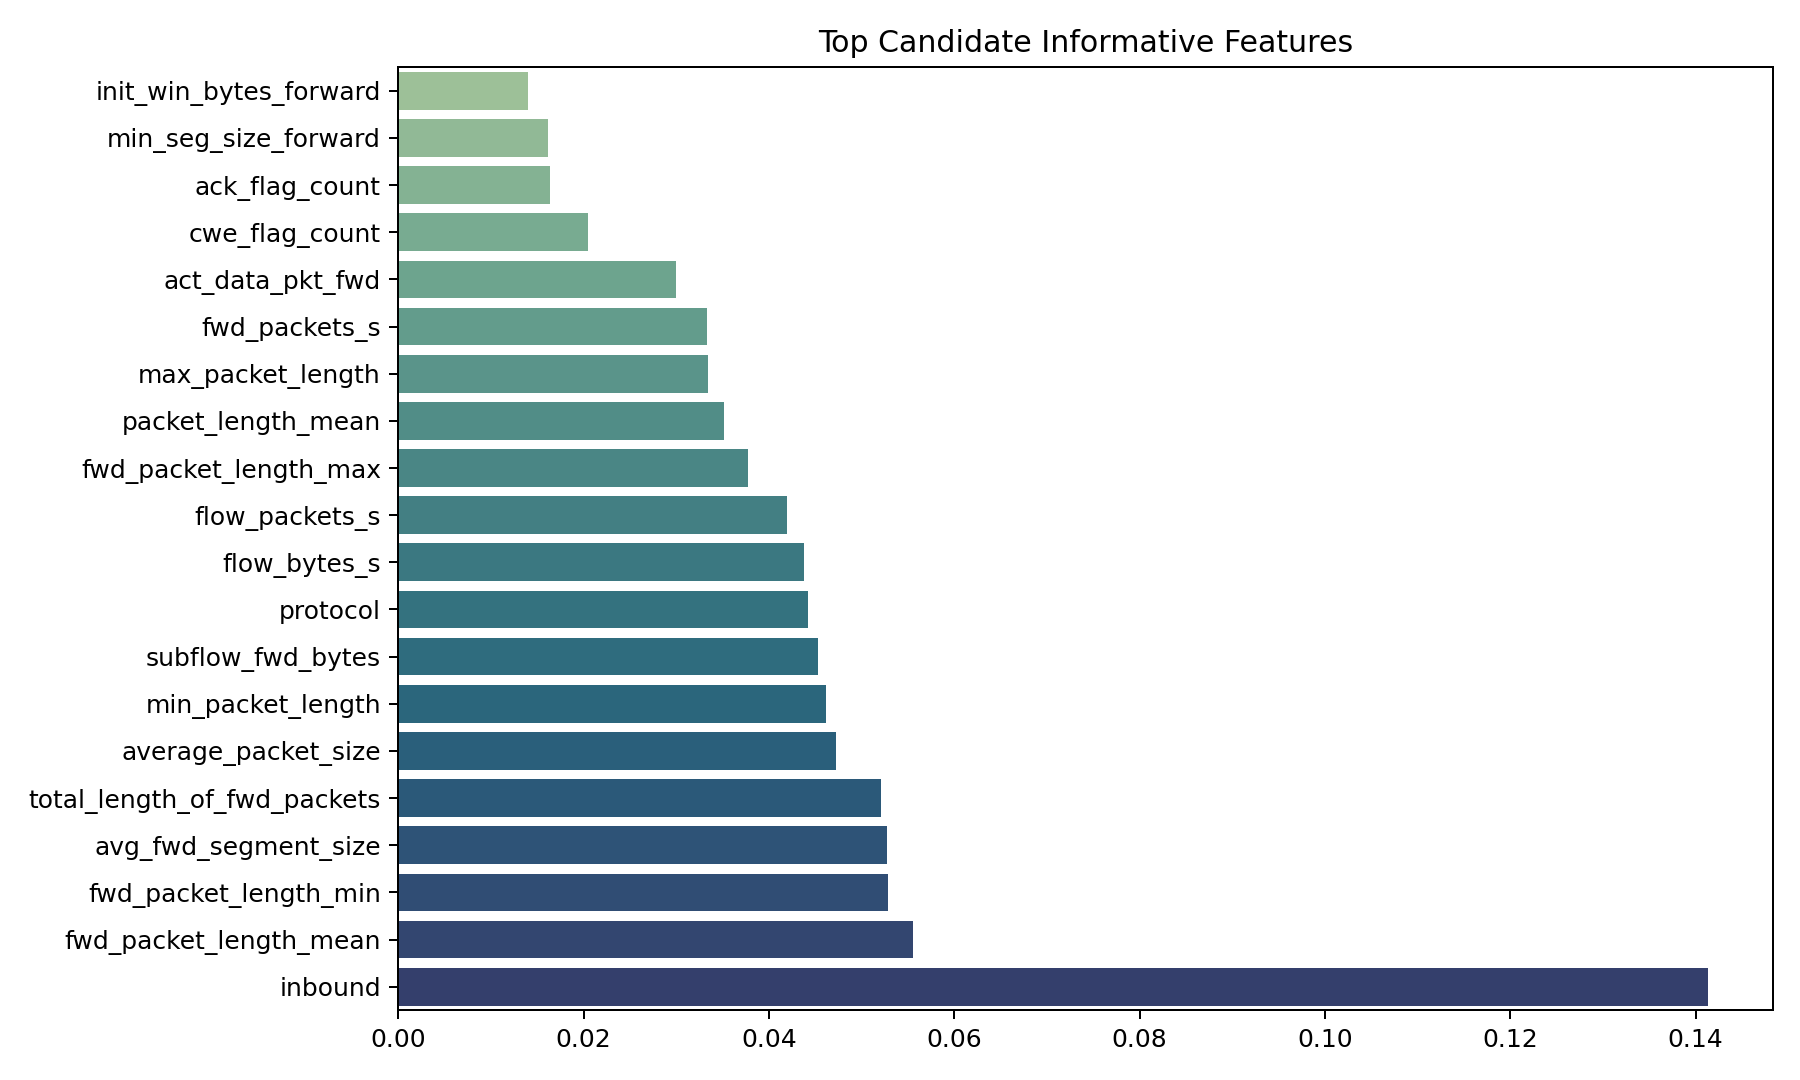

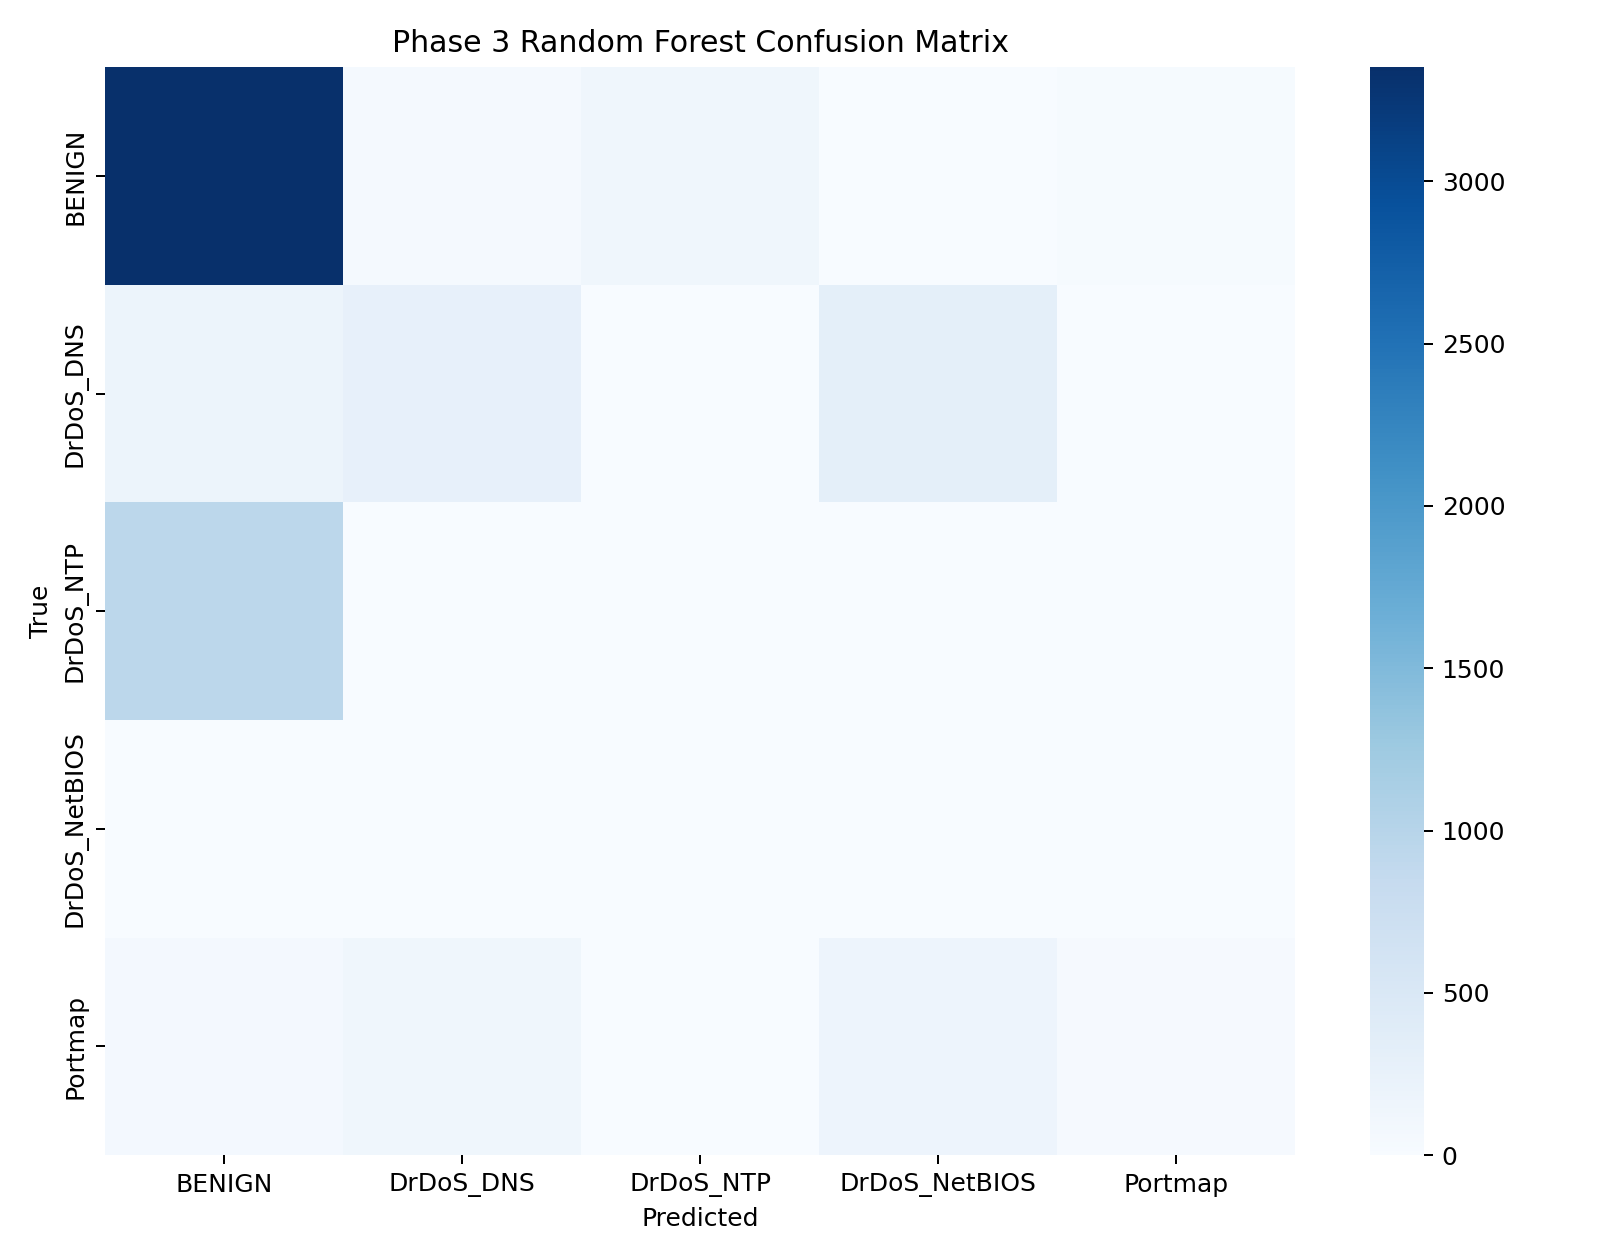

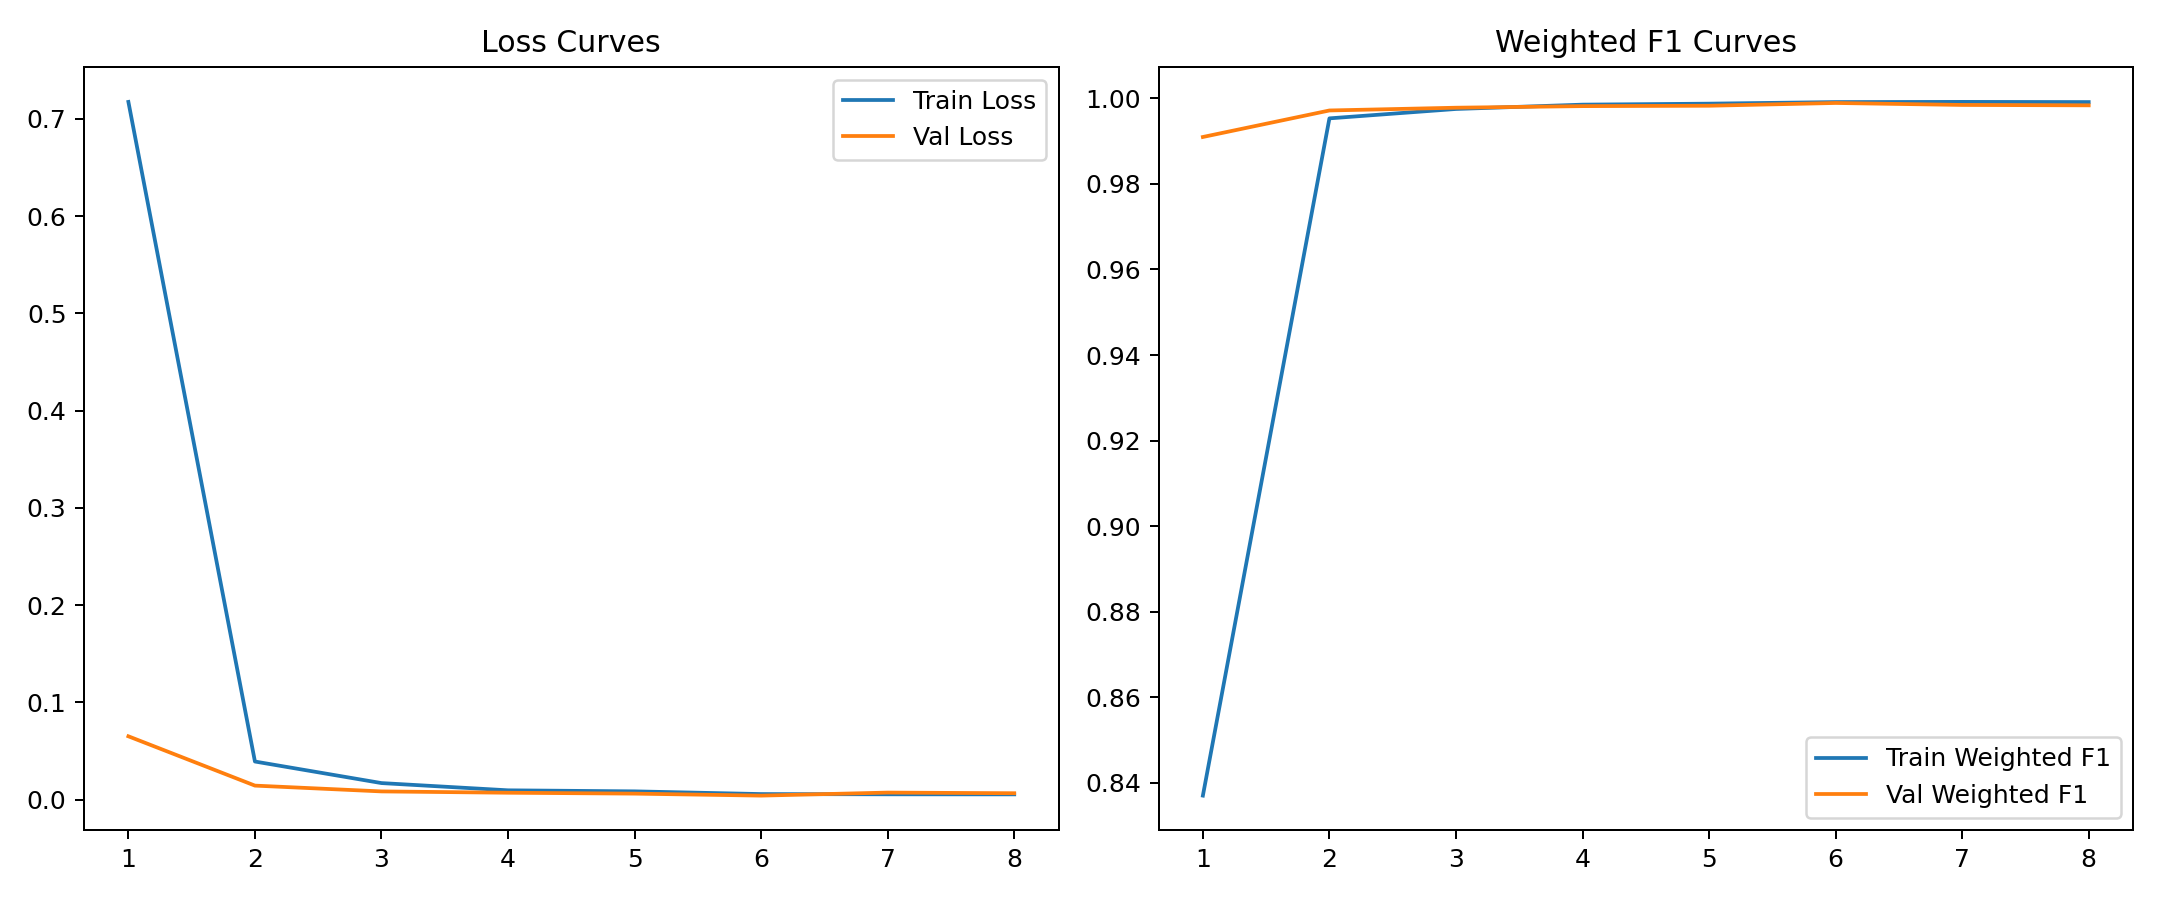

In [24]:
# Show the saved Phase 3 figures.

display(Image(filename=str(PHASE3_OUTPUT_DIR / 'candidate_feature_importance.png')))
display(Image(filename=str(PHASE3_OUTPUT_DIR / 'random_forest_confusion_matrix.png')))
display(Image(filename=str(PHASE3_OUTPUT_DIR / 'lstm_training_curves.png')))

### Phase 3 Interpretation

Phase 3 strengthens the main lesson of the project.

The very strong Phase 2 results were informative as a pipeline benchmark, but they were optimistic. Once evaluation is constrained by strict `source_ip` separation, the project reveals real generalization limits:
- attack traffic is concentrated in very few source-IP groups
- some attack classes have extremely fragile held-out support
- shortcut features such as `inbound` can hurt robustness
- model choice matters more than it appeared under row-wise splitting

Methodologically, Phase 3 is important because it separates **high benchmark performance** from **credible generalization analysis**. In this setting, evaluation strategy is not a minor detail; it changes the scientific interpretation of the project.

## Final Conclusion

This notebook now documents the project across four complementary stages without changing the validated script-based pipeline.

What has been achieved:
- Phase 1 validated the binary pipeline end to end.
- Phase 1 ablation showed that removing `inbound` does not collapse the easy binary benchmark.
- Phase 2 validated a multiclass setup on four audited attack files and serves as the main row-wise benchmark.
- Phase 2.5 established that a strict three-way `source_ip`-aware split is infeasible for this dataset slice.
- Phase 2.5b delivered the strongest feasible robustness check through a strict 2-way `source_ip`-aware train/test split.
- Phase 3 added feature ablation and model analysis under that same strict protocol.

How the phases should now be interpreted:
- **Phase 2** is the multiclass benchmark under a practical but optimistic row-wise split.
- **Phase 2.5b** is the stricter robustness check for unseen `source_ip` groups.
- **Phase 3** is the generalization-analysis stage that tests shortcut features, compares model families, and examines whether LSTM is truly justified.

Final recommendation:
- use **group-aware evaluation** whenever claiming robustness on CIC-DDoS2019
- avoid shortcut-heavy features such as **`inbound`** when they reduce generalization
- treat **Random Forest** as the strongest practical model in the current strict-evaluation setting
- treat **LSTM** as an informative experimental model rather than the default best choice for this tabular flow dataset

Final methodological conclusion:
- the project pipeline is valid, reproducible, and well-audited
- benchmark performance and robustness performance must be reported separately
- CIC-DDoS2019 can look deceptively easy under row-wise splitting because attack traffic is concentrated in very few source-IP groups